# Tabular models: logistic regression and random forest

Interactive companion to `reports/tabular/README.md` (the written report with all figures).
The models are trained by the pipeline, not here:

    python -m forest_fire_risk.tabular            # tune + train + evaluate -> reports/tabular/
    python -m forest_fire_risk.side_experiments   # optional
    python -m forest_fire_risk.tabular_figures    # figures

This notebook loads those results and shows how to work with them.

| Years | Role | Used to |
|---|---|---|
| 2017-2019 | train | fit; leave-one-year-out CV (k = 3) picks hyperparameters and threshold |
| 2020 | fusion only | the final LR / RF only predict it; never used to fit or tune them |
| 2021-2022 | test | scored once, at the end |

In [1]:
import json
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import Image, display

from forest_fire_risk.tabular import FEATURES, MAX_CLOUD, MODEL_DIR, REPORT_DIR, load_data, season_weights, scores

FIG = REPORT_DIR / "figures"
pd.set_option("display.precision", 3)

## 1. The data: tabular rows that also have a Sentinel-2 tile

In [2]:
tab = load_data()
print(f"{len(tab):,} samples with a tile (scene cloud <= {MAX_CLOUD}%), {len(FEATURES)} fire-day features")
pd.crosstab(tab.split, tab.label, margins=True).rename(columns={0: "no fire", 1: "fire"})

10,922 samples with a tile (scene cloud <= 20%), 27 fire-day features


label,no fire,fire,All
split,,,
test,2439,1319,3758
train,3267,1799,5066
val,1357,741,2098
All,7063,3859,10922


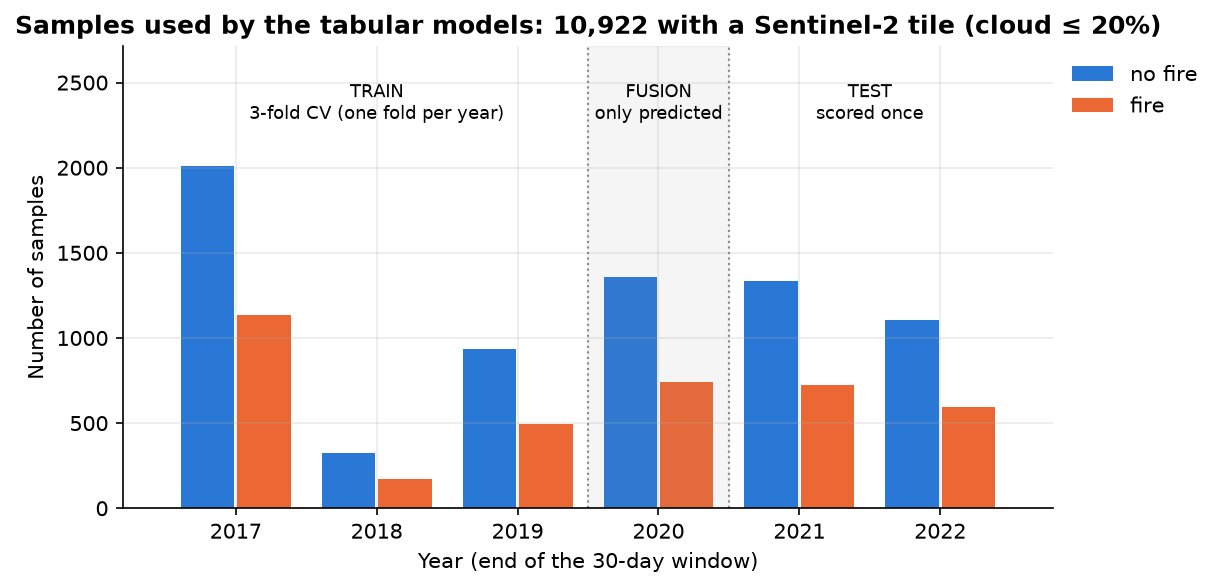

In [3]:
display(Image(FIG / "01_data_split.png"))

## 2. Chosen settings (from cross-validation on 2017-19)

In [4]:
best = json.loads((REPORT_DIR / "best_params.json").read_text())
pd.DataFrame({m: {"settings": v["params"], "CV AUPRC": round(v["cv_auprc"], 3),
                  "threshold": round(v["threshold"], 3)} for m, v in best.items()}).T

,settings,CV AUPRC,threshold
logreg,{'logisticregression__C': 0.1},0.684,0.343
rf,"{'randomforestclassifier__class_weight': None,...",0.785,0.369


## 3. Test results (2021-22), standard and season-matched

Season-matched = test non-fires re-weighted so their months follow the fires' months, which
removes the "fire season" shortcut. The month-only baseline drops to chance (ROC-AUC 0.5).

In [5]:
metrics = pd.read_csv(REPORT_DIR / "metrics.csv")
metrics.pivot(index="model", columns="evaluation", values=["auprc", "roc_auc", "f1"])

auprc                 roc_auc                      f1  \
evaluation season_matched standard season_matched standard season_matched   
model                                                                       
logreg              0.604    0.710          0.736    0.819          0.595   
month               0.351    0.554          0.500    0.757          0.472   
rf                  0.731    0.829          0.831    0.899          0.671   

                     
evaluation standard  
model                
logreg        0.673  
month         0.644  
rf            0.758

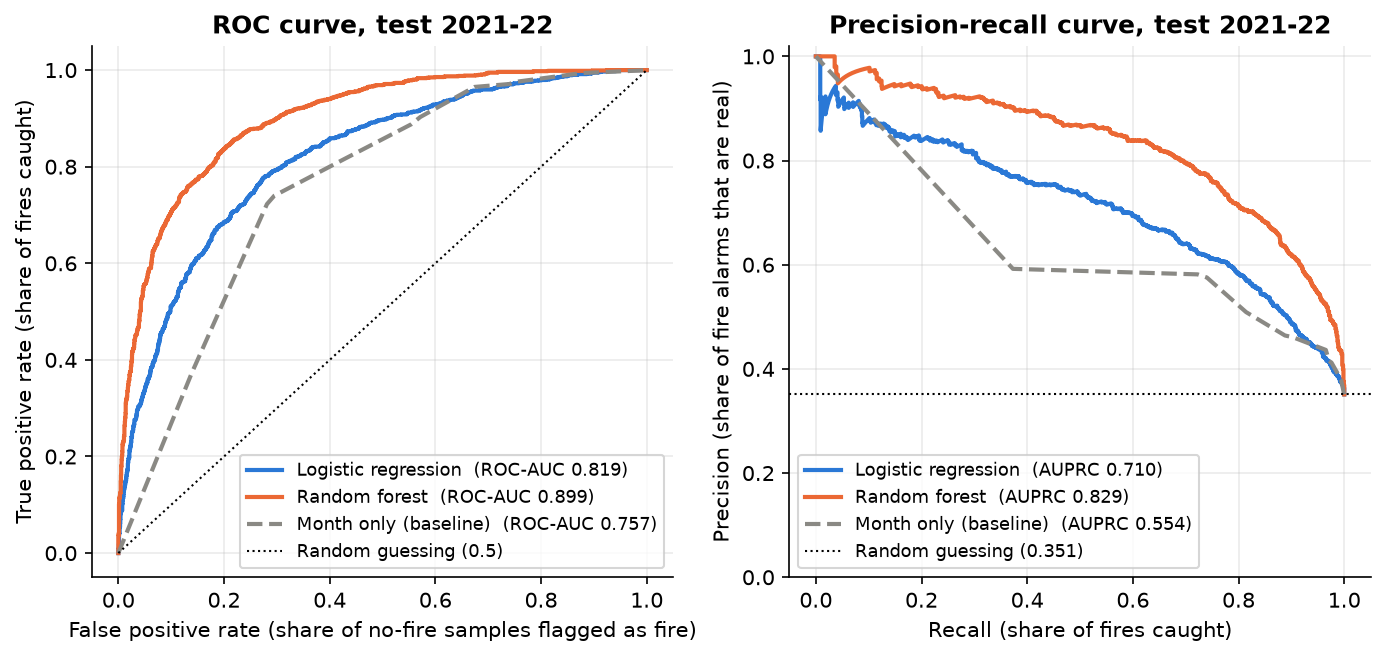

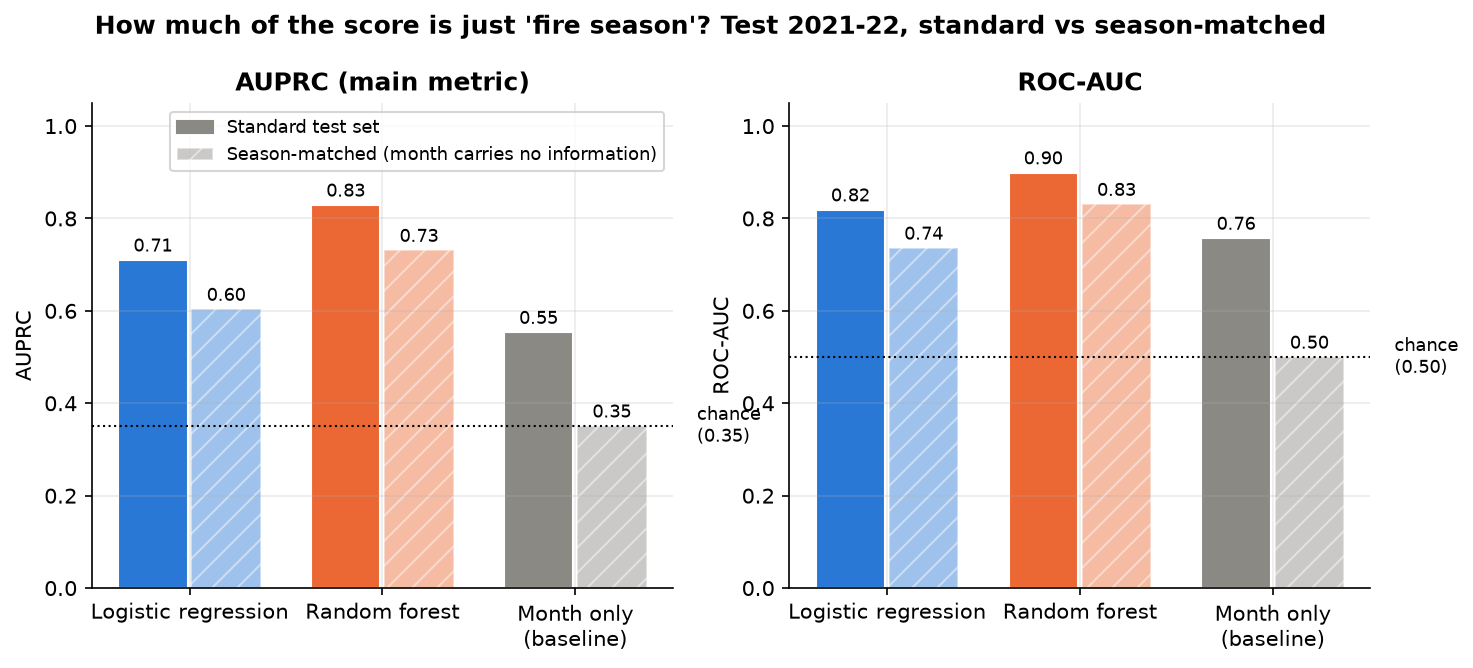

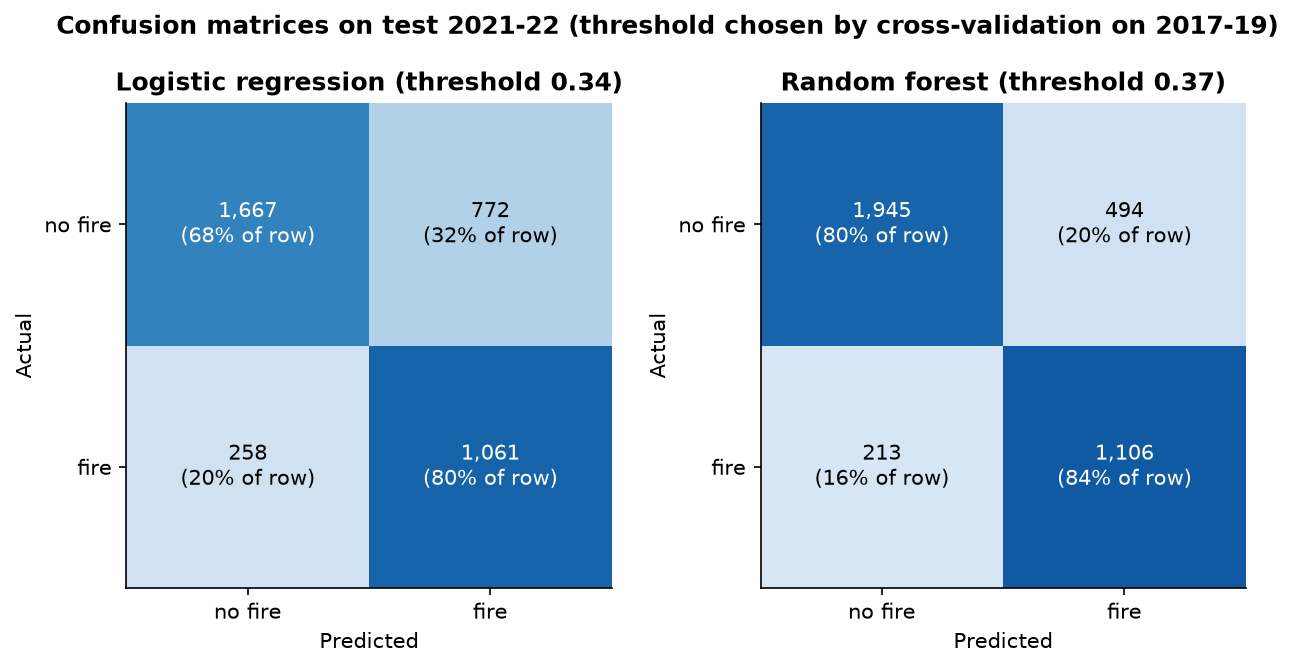

In [6]:
for f in ["02_roc_pr_curves.png", "03_season_matched.png", "04_confusion_matrices.png"]:
    display(Image(FIG / f))

## 4. Using the saved models

The fitted pipelines (imputer [+ scaler] + model) are in `models/tabular/`. They take the
27 raw features, so any row from `to_tabular` can be scored directly. Here: recompute the
random forest's test scores from scratch, plain and season-matched.

In [7]:
rf = joblib.load(MODEL_DIR / "rf.joblib")
test = tab[tab.split == "test"]
p = rf.predict_proba(test[FEATURES])[:, 1]
pd.DataFrame({"standard": scores(test.label, p, best["rf"]["threshold"]),
              "season_matched": scores(test.label, p, best["rf"]["threshold"],
                                       season_weights(test.label, test.month))})

,standard,season_matched
auprc,0.829,0.731
roc_auc,0.899,0.831
f1,0.758,0.671
precision,0.691,0.560
recall,0.839,0.839
threshold,0.369,0.369


## 5. What drives the predictions

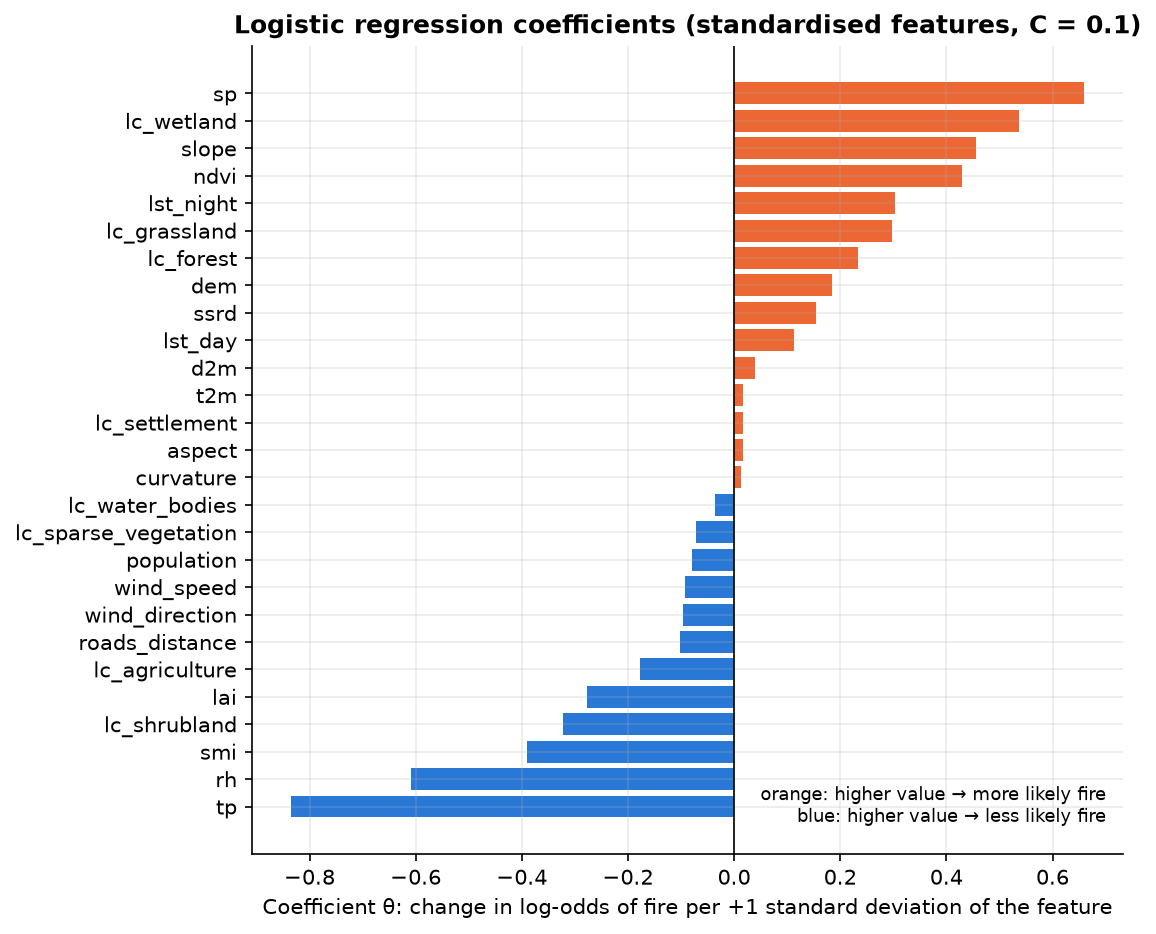

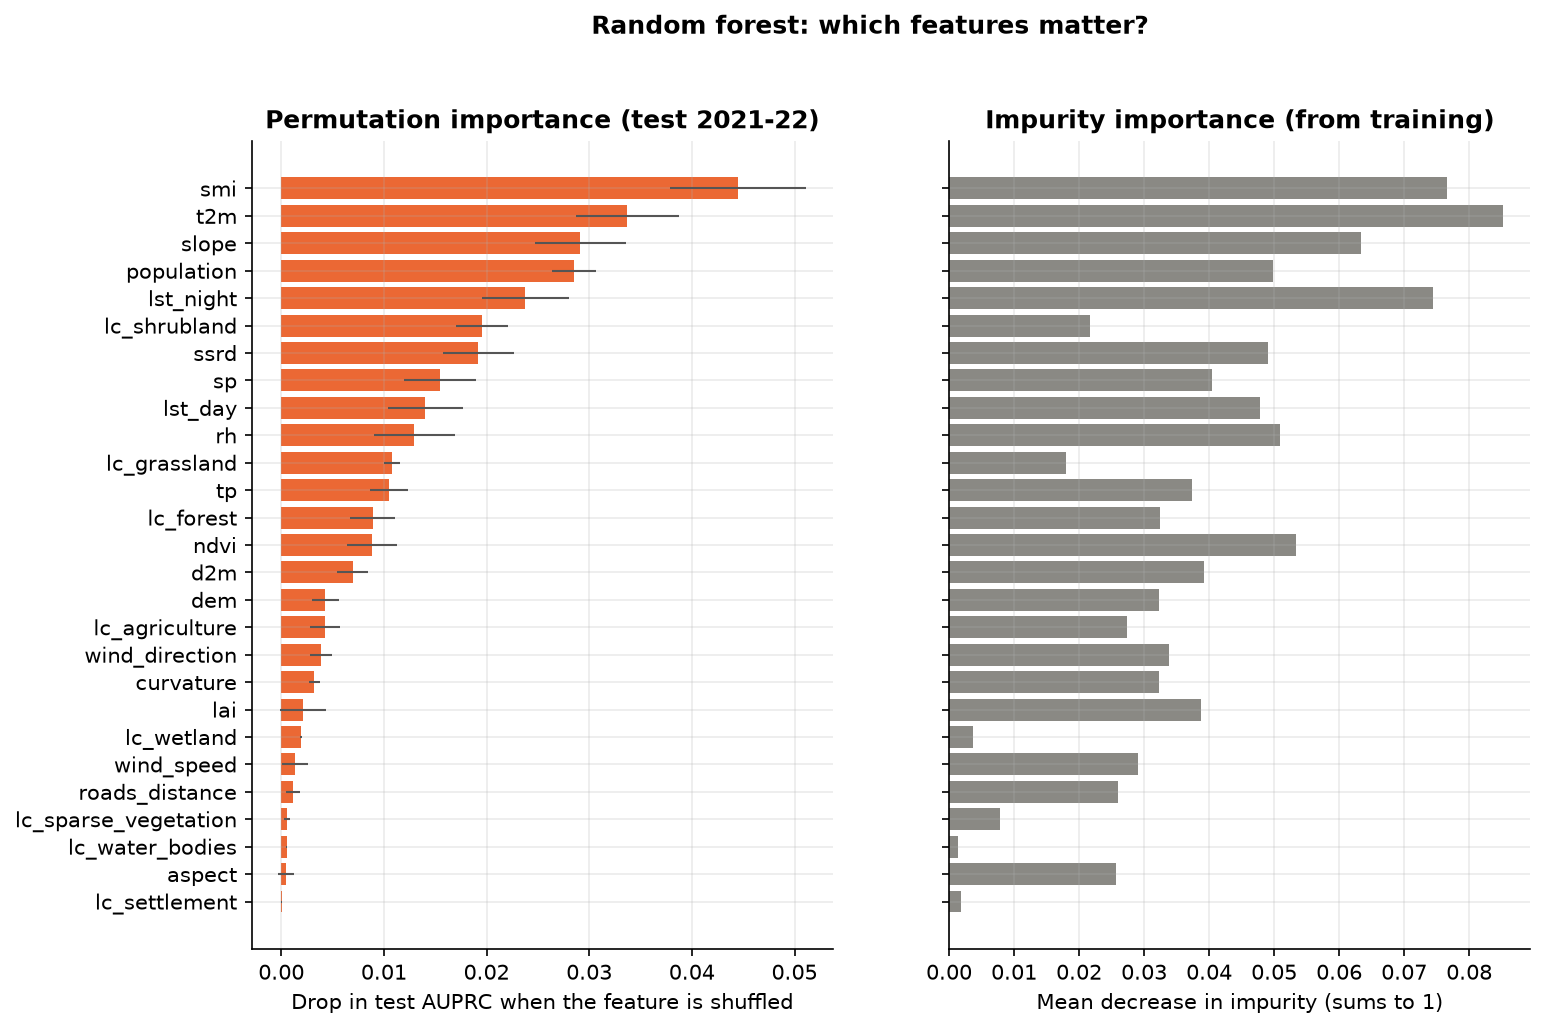

,perm,perm_sd,gini
smi,0.045,0.007,0.077
t2m,0.034,0.005,0.085
slope,0.029,0.004,0.063
population,0.029,0.002,0.050
lst_night,0.024,0.004,0.074
lc_shrubland,0.020,0.003,0.022
ssrd,0.019,0.003,0.049
sp,0.015,0.004,0.040
lst_day,0.014,0.004,0.048
rh,0.013,0.004,0.051


In [8]:
for f in ["05_lr_coefficients.png", "06_rf_feature_importance.png"]:
    display(Image(FIG / f))
pd.read_csv(REPORT_DIR / "rf_feature_importance.csv", index_col=0).head(10)

## 6. Predictions for the fusion model

`predictions.csv`: one row per 2020 (`val`, to train fusion) and 2021-22 (`test`) sample.
Join the CNN's predictions on `sample_id`.

In [9]:
preds = pd.read_csv(REPORT_DIR / "predictions.csv")
print(preds.split.value_counts().to_dict())
preds.head()

{'test': 3758, 'val': 2098}


,sample_id,label,time,split,p_logreg,p_rf
0,neg_13053,0,2020-01-01,val,0.010,0.069
1,neg_13054,0,2020-01-02,val,0.098,0.298
2,neg_13055,0,2020-01-02,val,0.015,0.027
3,neg_13056,0,2020-01-03,val,0.012,0.068
4,neg_13057,0,2020-01-03,val,0.042,0.031


## 7. Side experiments (not part of the main pipeline, not used by fusion)

evaluation         season_matched  standard
experiment model                           
all_years  logreg           0.614     0.731
           rf               0.739     0.830
main       logreg           0.604     0.710
           rf               0.731     0.829
mean7      logreg           0.660     0.734
           rf               0.729     0.831

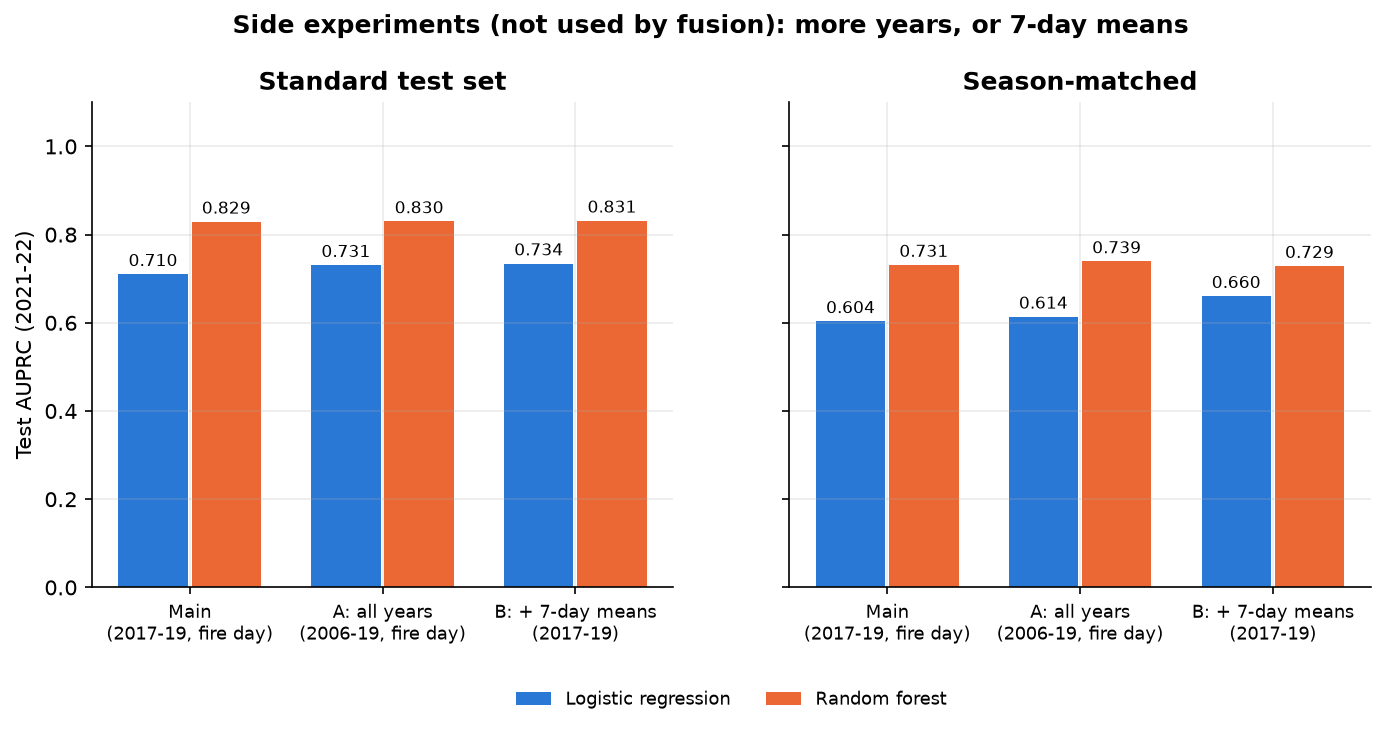

In [10]:
side = REPORT_DIR / "side_experiments.csv"
if side.exists():
    display(pd.read_csv(side).pivot_table(index=["experiment", "model"], columns="evaluation", values="auprc"))
    display(Image(FIG / "10_side_experiments.png"))